In [2]:
import pandas as pd   # la bibliothèque de manipulation de données tabulaires

import numpy as np   #la bibliothèque de calcul numérique

import matplotlib.pyplot as plt     #la bibliothèque de base pour les graphiques

import seaborn as sns      #Elle produit des graphiques statistiques plus esthétiques et patplotlib.lus rapides à écrire

from scipy import stats    #Importe uniquement le sous-module stats de SciPy. Il contient les tests statistiques que tu utilises plus loin

import os    #Il permet d’interagir avec le système de fichiers : créer des dossiers, lister des fichiers

import warnings   #gère les messages d’avertissement de Python

warnings.filterwarnings("ignore")   #Dit à Python de masquer tous les avertissements

sns.set_theme(style="whitegrid", palette="Set2")  #Définit le thème global de tous les graphiques seaborn et matplotlib

plt.rcParams["figure.figsize"] = (8, 5)   #Modifie un paramètre par défaut de Matplotlib, Ici, la taille par défaut d’une figure

os.makedirs("../reports/figures", exist_ok=True)  #Crée le dossier où seront sauvegardées tes images: 

df = pd.read_csv("../data/healthcare-dataset-stroke-data.csv")  #lit un fichier CSV et le transforme en DataFrame

print("1. DIMENSIONS DU DATASET")
print(df.shape)

print("2. APERÇU DES 5 PREMIÈRES LIGNES")
display(df.head())

print("3. INFORMATIONS SUR LES COLONNES (types et valeurs non nulles)")
df.info()

print("4. STATISTIQUES DESCRIPTIVES")
df.describe().T

1. DIMENSIONS DU DATASET
(5110, 12)
2. APERÇU DES 5 PREMIÈRES LIGNES


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


3. INFORMATIONS SUR LES COLONNES (types et valeurs non nulles)
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB
4. STATISTIQUES DESCRIPTIVES


,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.00,17741.250,36932.000,54682.00,72940.00
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,28.893237,7.854067,10.30,23.500,28.100,33.10,97.60
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00


In [ ]:
print("1.1 DÉFINITION DES TYPES DE VARIABLES")

num_cols = ["age", "avg_glucose_level", "bmi"]
bin_cols = ["hypertension", "heart_disease"]
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
target = "stroke"   #contient le nom de la colonne à prédire.

print("Variables numériques    :", num_cols)
print("Variables binaires      :", bin_cols)
print("Variables catégorielles :", cat_cols)
print("Variable cible          :", target)

print("1.2 RECHERCHE DE DOUBLONS")

print("Doublons (lignes entières) :", df.duplicated().sum())  #df.duplicated() renvoie une série de True/False : True si la ligne est identique à une ligne précédente.

print("Doublons sur id            :", df["id"].duplicated().sum())

1.1 DÉFINITION DES TYPES DE VARIABLES
Variables numériques    : ['age', 'avg_glucose_level', 'bmi']
Variables binaires      : ['hypertension', 'heart_disease']
Variables catégorielles : ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
Variable cible          : stroke
1.2 RECHERCHE DE DOUBLONS
Doublons (lignes entières) : 0
Doublons sur id            : 0


In [ ]:
print("2.1 VALEURS MANQUANTES")

missing = df.isnull().sum()  #additionne par colonne
missing_pct = (missing / len(df) * 100).round(2)    #len(df) est le nombre de lignes
missing_table = pd.DataFrame({"manquants": missing, "%": missing_pct})
display(missing_table[missing_table["manquants"] > 0])

print("2.1b TAUX D'AVC SELON LA PRÉSENCE / ABSENCE DE BMI")

print("(False = bmi renseigné, True = bmi manquant)")
display(df.groupby(df["bmi"].isnull())[target].mean())

2.1 VALEURS MANQUANTES


,manquants,%
bmi,201,3.93


2.1b TAUX D'AVC SELON LA PRÉSENCE / ABSENCE DE BMI
(False = bmi renseigné, True = bmi manquant)


bmi
False    0.042575
True     0.199005
Name: stroke, dtype: float64

In [5]:
print("2.2 MODALITÉS DE CHAQUE VARIABLE CATÉGORIELLE")

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())

print("2.2b ÂGE DES PATIENTS AVEC smoking_status = 'Unknown'")

display(df[df["smoking_status"] == "Unknown"]["age"].describe())

2.2 MODALITÉS DE CHAQUE VARIABLE CATÉGORIELLE

--- gender ---
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

--- ever_married ---
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

--- work_type ---
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

--- Residence_type ---
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

--- smoking_status ---
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64
2.2b ÂGE DES PATIENTS AVEC smoking_status = 'Unknown'


count    1544.000000
mean       30.229922
std        25.055556
min         0.080000
25%         8.000000
50%        23.000000
75%        51.000000
max        82.000000
Name: age, dtype: float64

2.3a BOXPLOTS POUR REPÉRER LES OUTLIERS


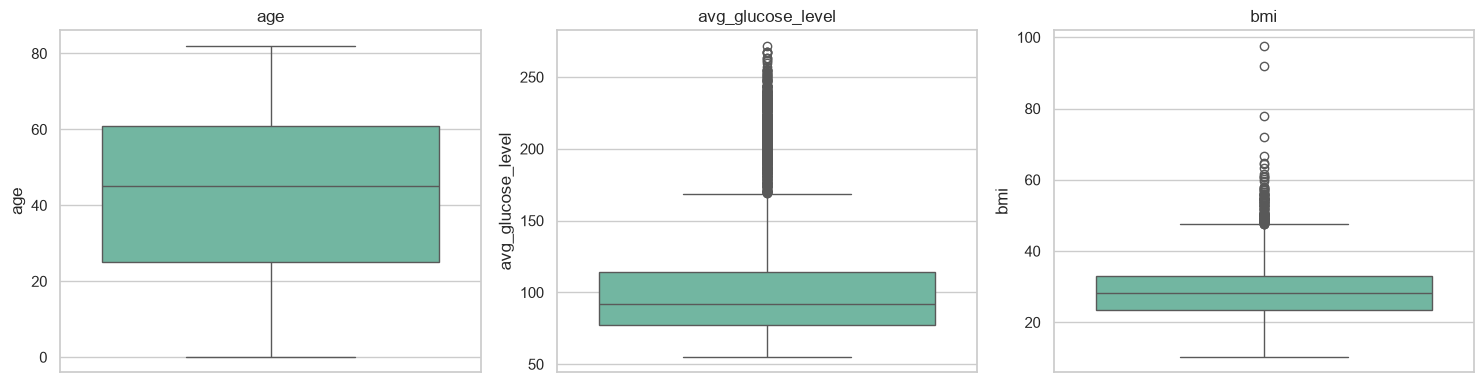

In [ ]:
print("2.3a BOXPLOTS POUR REPÉRER LES OUTLIERS")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):    #zip associe les éléments deux par deux : (zone 1, age), (zone 2, avg_glucose_level), (zone 3, bmi)
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("../reports/figures/01_boxplots_outliers.png", dpi=150)
plt.show()

In [ ]:
print("2.3b OUTLIERS PAR LA MÉTHODE IQR")

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_out} outliers ({n_out/len(df)*100:.1f} %) | bornes [{low:.1f}, {high:.1f}]")

2.3b OUTLIERS PAR LA MÉTHODE IQR
age: 0 outliers (0.0 %) | bornes [-29.0, 115.0]
avg_glucose_level: 627 outliers (12.3 %) | bornes [22.0, 169.4]
bmi: 110 outliers (2.2 %) | bornes [9.1, 47.5]


In [8]:
print("2.3c VALEURS EXTRÊMES À VÉRIFIER")

print("10 plus grandes valeurs de bmi :", df["bmi"].sort_values(ascending=False).head(10).values)
print("Âge minimum :", df["age"].min())
print("Âge maximum :", df["age"].max())

2.3c VALEURS EXTRÊMES À VÉRIFIER
10 plus grandes valeurs de bmi : [97.6 92.  78.  71.9 66.8 64.8 64.4 63.3 61.6 61.2]
Âge minimum : 0.08
Âge maximum : 82.0


3. DISTRIBUTION DE LA VARIABLE CIBLE (stroke)


,effectif,%
stroke,,
0,4861,95.13
1,249,4.87


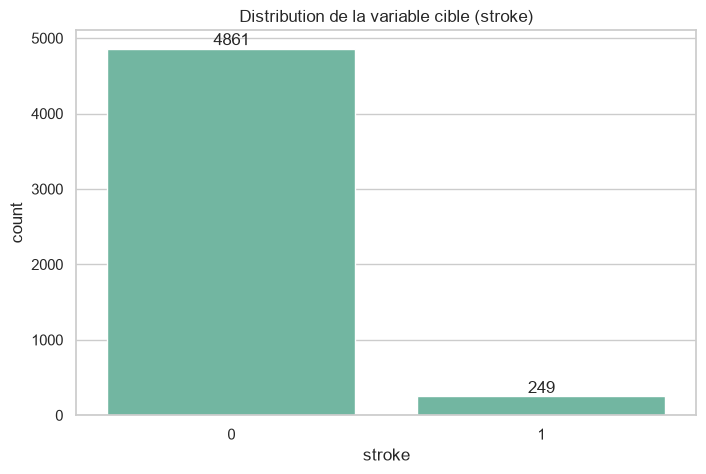

In [ ]:
print("3. DISTRIBUTION DE LA VARIABLE CIBLE (stroke)")

counts = df[target].value_counts()
pct = df[target].value_counts(normalize=True) * 100
display(pd.DataFrame({"effectif": counts, "%": pct.round(2)}))

ax = sns.countplot(x=target, data=df)
for p in ax.patches:    #ax.patches est la liste des barres du graphique. On les parcourt une par une.
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")     #Écrit la valeur au-dessus de chaque barre :
ax.set_title("Distribution de la variable cible (stroke)")
plt.savefig("../reports/figures/02_target_distribution.png", dpi=150)
plt.show()

4.1 DISTRIBUTION DES VARIABLES NUMÉRIQUES


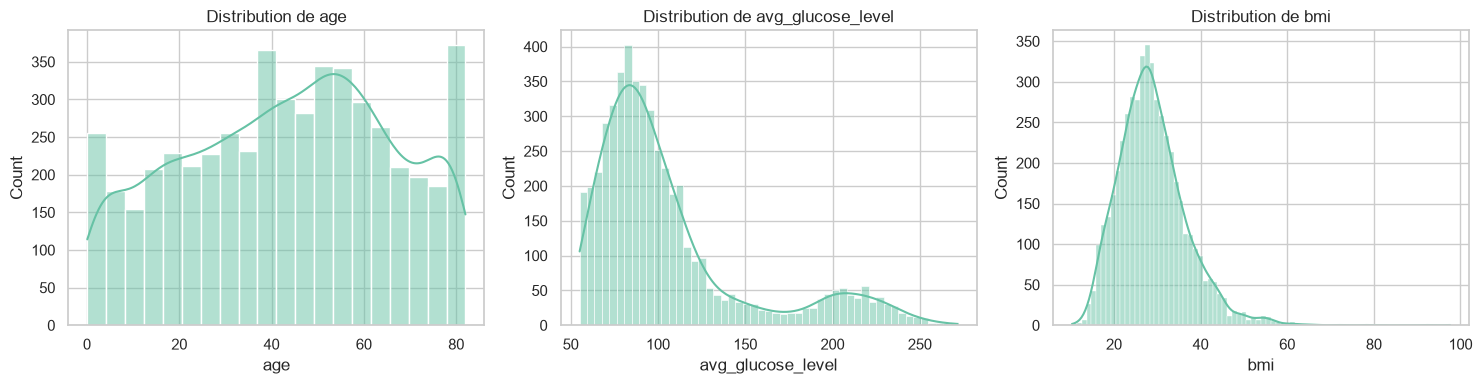


Asymétrie (skewness) de chaque variable :


age                 -0.137059
avg_glucose_level    1.572284
bmi                  1.055340
dtype: float64

In [ ]:
print("4.1 DISTRIBUTION DES VARIABLES NUMÉRIQUES")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax) #kde=True ajoute une courbe lisse qui montre la forme de la distribution.
    ax.set_title(f"Distribution de {col}")
plt.tight_layout()
plt.savefig("../reports/figures/03_num_distributions.png", dpi=150)
plt.show()

print("\nAsymétrie (skewness) de chaque variable :")
display(df[num_cols].skew())

4.2a BOXPLOTS DES VARIABLES NUMÉRIQUES SELON stroke


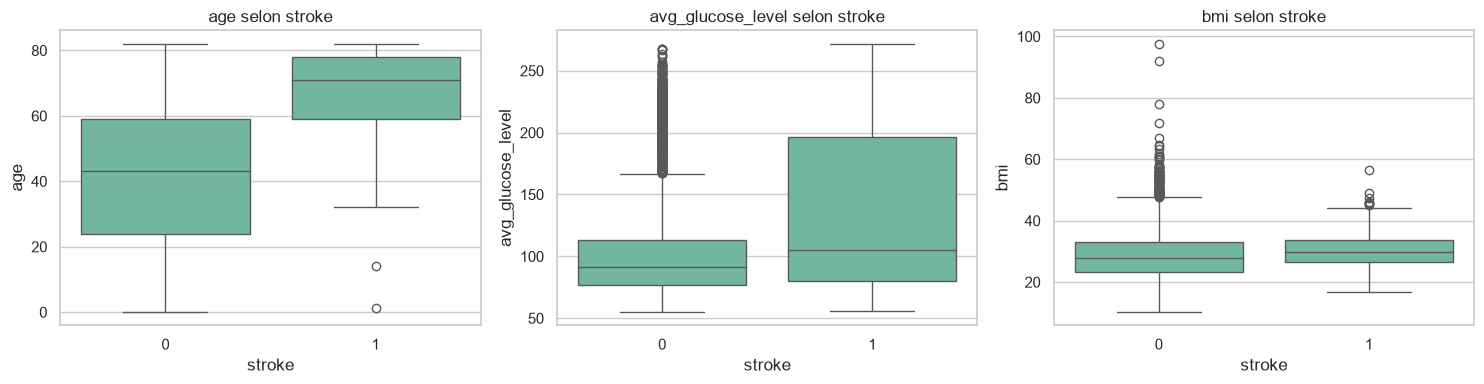

In [11]:
print("4.2a BOXPLOTS DES VARIABLES NUMÉRIQUES SELON stroke")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=target, y=col, data=df, ax=ax)
    ax.set_title(f"{col} selon stroke")
plt.tight_layout()
plt.savefig("../reports/figures/04_num_by_stroke.png", dpi=150)
plt.show()

4.2b COURBES DE DENSITÉ SELON stroke


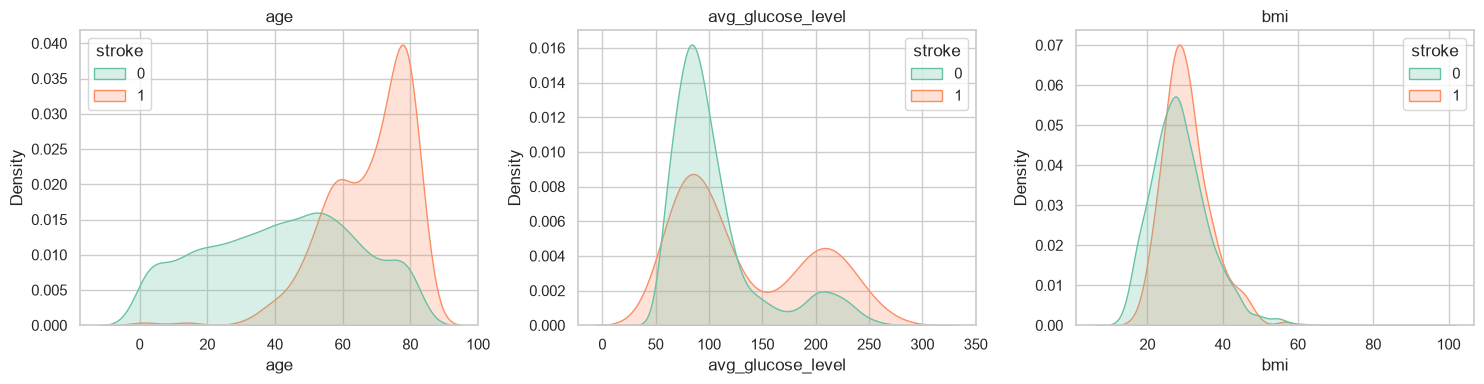

In [ ]:
print("4.2b COURBES DE DENSITÉ SELON stroke")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.kdeplot(data=df, x=col, hue=target, common_norm=False, fill=True, ax=ax)
    ax.set_title(col)    #hue=target : une courbe de couleur par classe.
    #common_norm=False : chaque classe est normalisée séparément. C’est indispensable ici : sans ça, la classe AVC (5 %) serait écrasée par l’autre et on ne verrait rien.
    
    #fill=True : colorie l’aire sous la courbe.
plt.tight_layout()
plt.savefig("../reports/figures/05_num_kde_by_stroke.png", dpi=150)
plt.show()

In [ ]:
print("4.3 TEST DE MANN-WHITNEY : AVC vs NON-AVC")
print("p < 0.05 => la variable diffère significativement entre les deux groupes\n")

rows = []
for col in num_cols:
    g0 = df[df[target] == 0][col].dropna()   #.dropna() retire les manquants
    g1 = df[df[target] == 1][col].dropna()
    stat, p = stats.mannwhitneyu(g0, g1)  #Test de Mann-Whitney : les deux groupes ont-ils la même distribution ? Il renvoie la statistique stat et la p-value p
    
    rows.append({"variable": col,
                 "moyenne (sans AVC)": round(g0.mean(), 2),
                 "moyenne (AVC)": round(g1.mean(), 2),
                 "p-value Mann-Whitney": p})
display(pd.DataFrame(rows))

4.3 TEST DE MANN-WHITNEY : AVC vs NON-AVC
p < 0.05 => la variable diffère significativement entre les deux groupes



,variable,moyenne (sans AVC),moyenne (AVC),p-value Mann-Whitney
0,age,41.97,67.73,3.726635e-71
1,avg_glucose_level,104.80,132.54,3.640367e-09
2,bmi,28.82,30.47,1.026429e-04


4.4 TAUX D'AVC PAR TRANCHE D'ÂGE


age_group
<18       0.22
18-40     0.45
40-60     4.10
60-80    12.96
80+      19.83
Name: stroke, dtype: float64

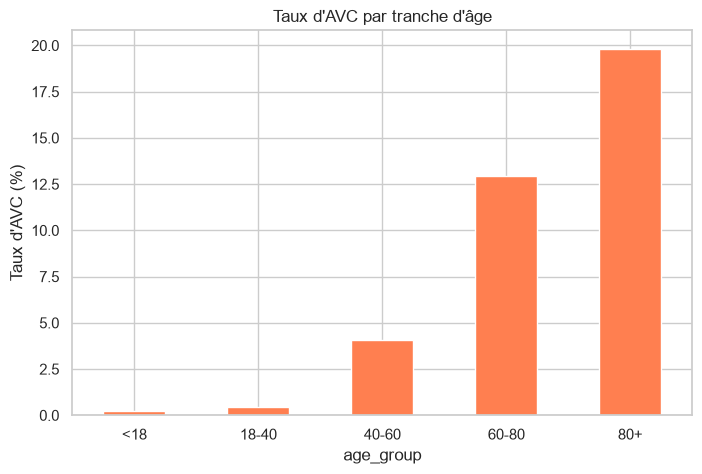

In [14]:
print("4.4 TAUX D'AVC PAR TRANCHE D'ÂGE")

df["age_group"] = pd.cut(df["age"], bins=[0, 18, 40, 60, 80, 100],
                         labels=["<18", "18-40", "40-60", "60-80", "80+"])
rate = df.groupby("age_group", observed=True)[target].mean() * 100
display(rate.round(2))

rate.plot(kind="bar", color="coral")
plt.ylabel("Taux d'AVC (%)")
plt.title("Taux d'AVC par tranche d'âge")
plt.xticks(rotation=0)
plt.savefig("../reports/figures/06_stroke_rate_by_age.png", dpi=150)
plt.show()

5.1 DISTRIBUTION DES VARIABLES CATÉGORIELLES ET BINAIRES


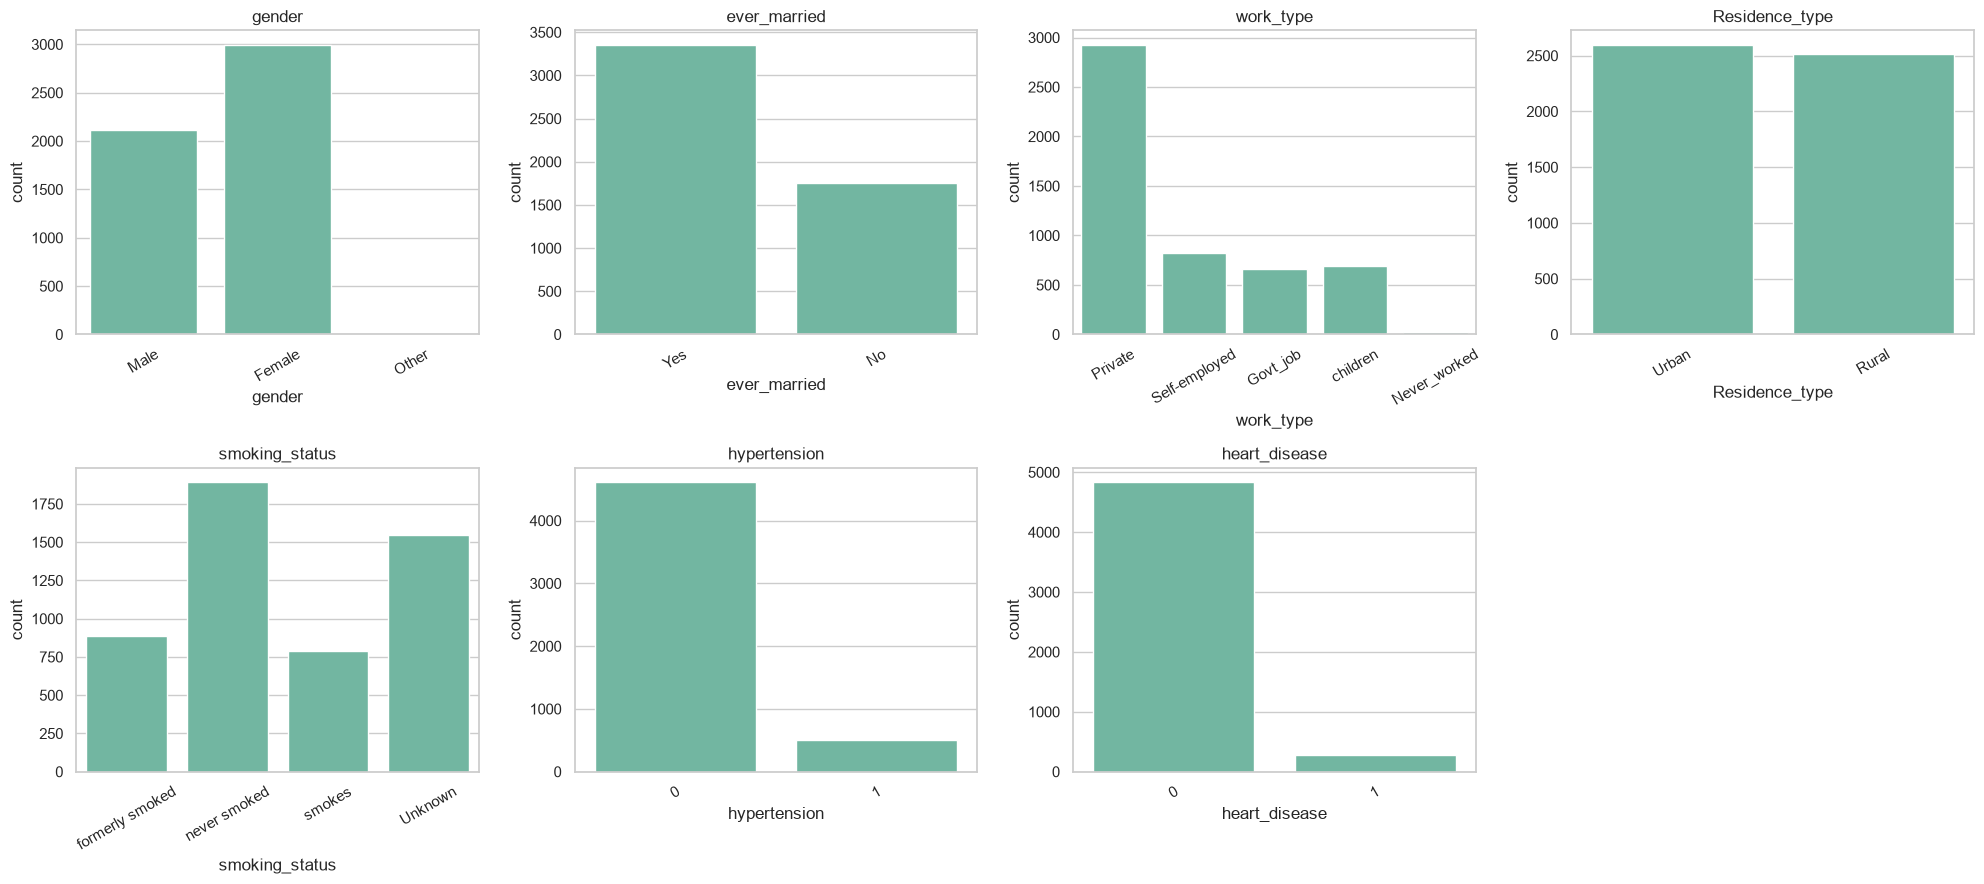

In [15]:
print("5.1 DISTRIBUTION DES VARIABLES CATÉGORIELLES ET BINAIRES")

all_cat = cat_cols + bin_cols
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, all_cat):
    sns.countplot(x=col, data=df, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig("../reports/figures/07_cat_distributions.png", dpi=150)
plt.show()

5.2 TAUX D'AVC (%) PAR MODALITÉ DE CHAQUE VARIABLE


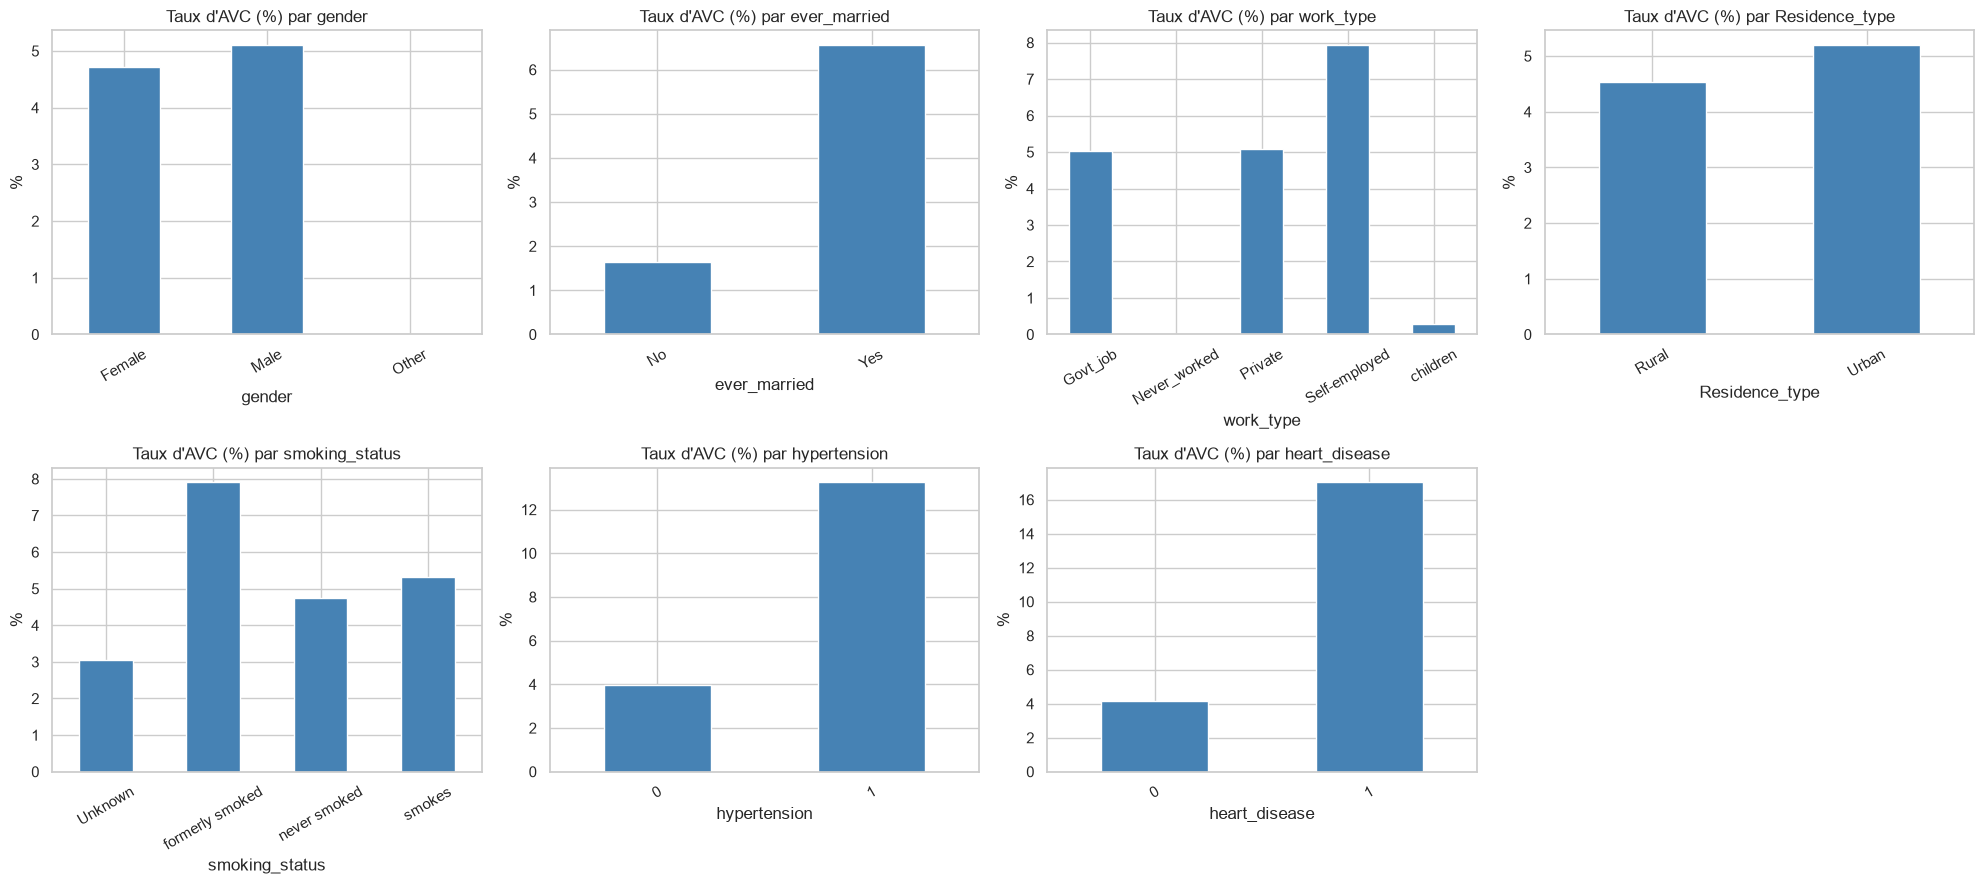

In [16]:
print("5.2 TAUX D'AVC (%) PAR MODALITÉ DE CHAQUE VARIABLE")

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, all_cat):
    rate = df.groupby(col)[target].mean() * 100
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"Taux d'AVC (%) par {col}")
    ax.set_ylabel("%")
    ax.tick_params(axis="x", rotation=30)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig("../reports/figures/08_stroke_rate_by_cat.png", dpi=150)
plt.show()

In [ ]:
print("5.3 TEST DU CHI² : LIEN ENTRE CHAQUE VARIABLE ET stroke")

print("p < 0.05 => lien statistiquement significatif avec l'AVC\n")

rows = []
for col in all_cat:
    table = pd.crosstab(df[col], df[target])   #Crée le tableau de contingence
    chi2, p, dof, _ = stats.chi2_contingency(table)   #Le test renvoie 4 valeurs : la statistique chi², la p-value, les degrés de liberté (dof), et le tableau des effectifs attendus
    
    rows.append({"variable": col, "chi2": round(chi2, 2), "p-value": p,
                 "significatif (p<0.05)": p < 0.05})
display(pd.DataFrame(rows).sort_values("p-value"))

5.3 TEST DU CHI² : LIEN ENTRE CHAQUE VARIABLE ET stroke
p < 0.05 => lien statistiquement significatif avec l'AVC



,variable,chi2,p-value,significatif (p<0.05)
6,heart_disease,90.26,2.088785e-21,True
5,hypertension,81.61,1.661622e-19,True
1,ever_married,58.92,1.638902e-14,True
2,work_type,49.16,5.397708e-10,True
4,smoking_status,29.15,2.085400e-06,True
3,Residence_type,1.08,2.983317e-01,False
0,gender,0.47,7.895491e-01,False


6.1 MATRICE DE CORRÉLATION


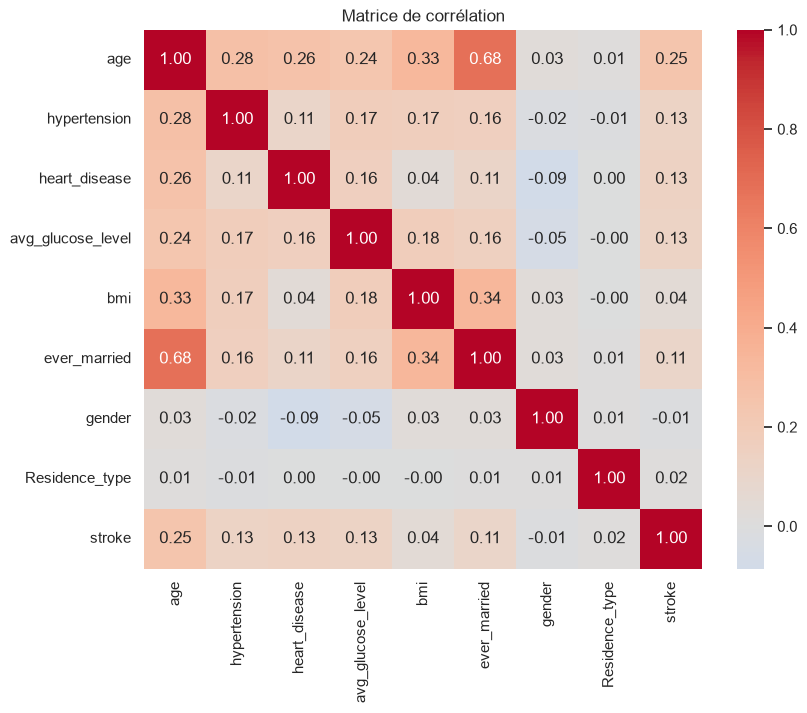

In [ ]:
print("6.1 MATRICE DE CORRÉLATION")

df_corr = df.copy()
df_corr["gender"] = df_corr["gender"].map({"Male": 0, "Female": 1, "Other": np.nan})
df_corr["ever_married"] = df_corr["ever_married"].map({"No": 0, "Yes": 1})
df_corr["Residence_type"] = df_corr["Residence_type"].map({"Rural": 0, "Urban": 1})

corr_cols = ["age", "hypertension", "heart_disease", "avg_glucose_level",
             "bmi", "ever_married", "gender", "Residence_type", "stroke"]
corr = df_corr[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)  #annot=True écrit la valeur dans chaque case, fmt=".2f" avec 2 décimales.
#cmap="coolwarm" : bleu pour négatif, rouge pour positif.
#center=0 : le blanc correspond à 0.
plt.title("Matrice de corrélation")
plt.savefig("../reports/figures/09_correlation_heatmap.png", dpi=150)
plt.show()

In [19]:
print("6.2 CORRÉLATION DE CHAQUE VARIABLE AVEC stroke (ordre décroissant)")

display(corr["stroke"].drop("stroke").sort_values(ascending=False))

6.2 CORRÉLATION DE CHAQUE VARIABLE AVEC stroke (ordre décroissant)


age                  0.245257
heart_disease        0.134914
avg_glucose_level    0.131945
hypertension         0.127904
ever_married         0.108340
bmi                  0.042374
Residence_type       0.015458
gender              -0.009081
Name: stroke, dtype: float64

6.3 INTERACTION : ÂGE x HYPERTENSION / MALADIE CARDIAQUE


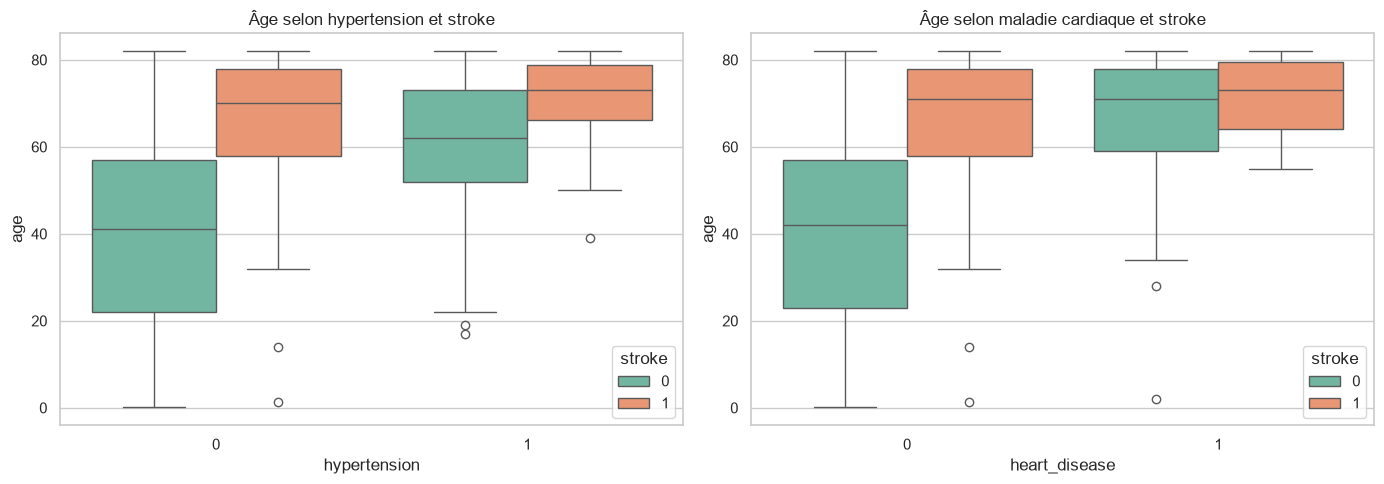

In [20]:
print("6.3 INTERACTION : ÂGE x HYPERTENSION / MALADIE CARDIAQUE")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x="hypertension", y="age", hue=target, data=df, ax=axes[0])
axes[0].set_title("Âge selon hypertension et stroke")
sns.boxplot(x="heart_disease", y="age", hue=target, data=df, ax=axes[1])
axes[1].set_title("Âge selon maladie cardiaque et stroke")
plt.tight_layout()
plt.savefig("../reports/figures/10_interaction_age.png", dpi=150)
plt.show()

6.4 RELATION GLUCOSE vs BMI (couleur = stroke)


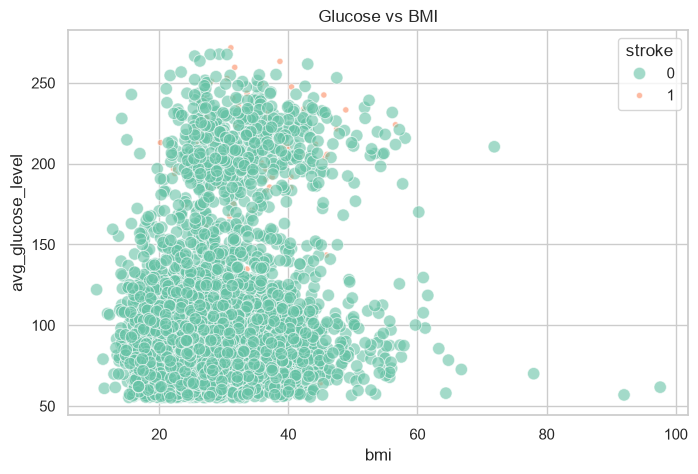

In [21]:
print("6.4 RELATION GLUCOSE vs BMI (couleur = stroke)")

sns.scatterplot(data=df, x="bmi", y="avg_glucose_level", hue=target,
                alpha=0.6, size=target, sizes=(20, 80))
plt.title("Glucose vs BMI")
plt.savefig("../reports/figures/11_scatter_glucose_bmi.png", dpi=150)
plt.show()